In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("fake_news_dataset")

print("Files inside the dataset:")
print(os.listdir("fake_news_dataset"))

Saving archive (1).zip to archive (1).zip
Files inside the dataset:
['WELFake_Dataset.csv']


In [3]:
import pandas as pd

df = pd.read_csv("fake_news_dataset/WELFake_Dataset.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Dataset loaded successfully!
Rows: 72134
Columns: 4


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [4]:
df.info()
print(df.columns.tolist())
df.isnull().sum()
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True) * 100)
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB
['Unnamed: 0', 'title', 'text', 'label']
label
1    37106
0    35028
Name: count, dtype: int64
label
1    51.440375
0    48.559625
Name: proportion, dtype: float64
Duplicate rows: 0


In [5]:
pd.set_option("display.max_colwidth", 200)

df[["title", "text", "label"]].head(10)

df["label"].unique()
pd.set_option("display.max_colwidth", 200)

df[["title", "text", "label"]].head(10)


,title,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF911 Terrorists [VIDEO],No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements called for the lynching and hanging of white people and cops. They encouraged others o...,1
1,NaN,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MOST CHARLOTTE RIOTERS WERE “PEACEFUL” PROTESTERS…In Her Home State Of North Carolina [VIDEO],"Now, most of the demonstrators gathered last night were exercising their constitutional and protected right to peaceful protest in order to raise issues and create change. Loretta Lynch aka Er...",1
3,"Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential 2016 bid",A dozen politically active pastors came here for a private dinner Friday night to hear a conversion story unique in the context of presidential politics: how Louisiana Gov. Bobby Jindal traveled f...,0
4,SATAN 2: Russia unvelis an image of its terrifying new ‘SUPERNUKE’ – Western world takes notice,"The RS-28 Sarmat missile, dubbed Satan 2, will replace the SS-18 Flies at 4.3 miles (7km) per sec and with a range of 6,213 miles (10,000km) The weapons are perceived as part of an increasingly ag...",1
5,About Time! Christian Group Sues Amazon and SPLC for Designation as Hate Group,"All we can say on this one is it s about time someone sued the Southern Poverty Law Center!On Tuesday, D. James Kennedy Ministries (DJKM) filed a lawsuit against the Southern Poverty Law Center (S...",1
6,DR BEN CARSON TARGETED BY THE IRS: “I never had an audit until I spoke at the National Prayer Breakfast.”,DR. BEN CARSON TELLS THE STORY OF WHAT HAPPENED WHEN HE SPOKE OUT AGAINST OBAMA:,1
7,HOUSE INTEL CHAIR On Trump-Russia Fake Story: “No evidence of anything” [Video],,1
8,Sports Bar Owner Bans NFL Games…Will Show Only ‘True American’ Sports: ‘I’d like to speak for rural America’ [Video],"The owner of the Ringling Bar, located south of White Sulphur Springs, is standing behind his Facebook post that criticizes NFL players who take a knee during the national anthem to protest police...",1
9,Latest Pipeline Leak Underscores Dangers Of Dakota Access Pipeline,"FILE – In this Sept. 15, 2005 file photo, the marker that welcomes commuters to Cushing, Okla. is seen. (AP Photo/The Oklahoman, Matt Strasen, File)\nUnderscoring once again the dangers of America...",1


In [6]:
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
Unnamed: 0      0
title         558
text           39
label           0
dtype: int64


In [7]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["label_encoded"] = label_encoder.fit_transform(df["label"])

print(df[["label", "label_encoded"]].drop_duplicates())
print(df["label_encoded"].value_counts())

   label  label_encoded
0      1              1
3      0              0
label_encoded
1    37106
0    35028
Name: count, dtype: int64


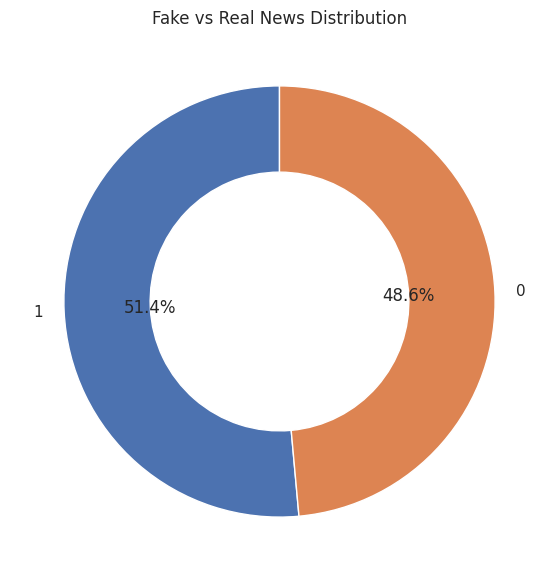

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df.head()
sns.set_theme(style="whitegrid")
label_counts = df["label"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    label_counts.values,
    labels=label_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Fake vs Real News Distribution")
plt.show()

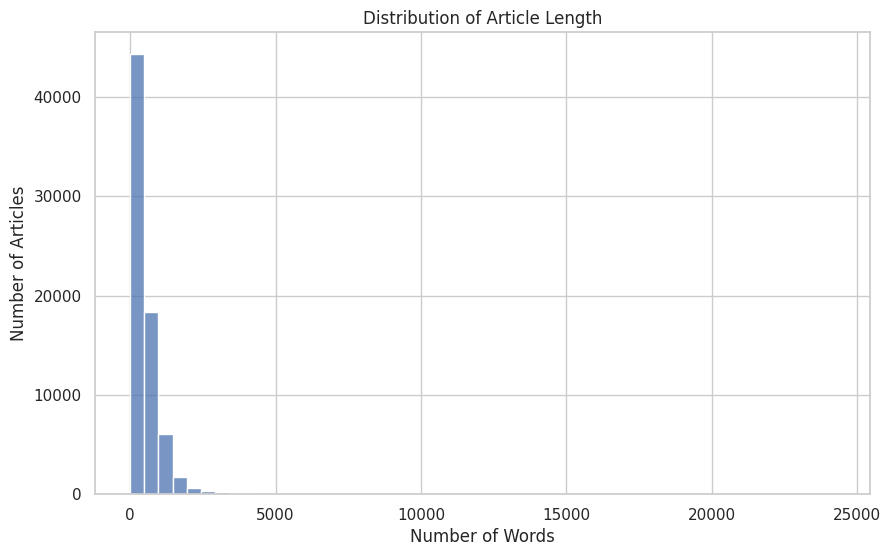

In [9]:
df["word_count"] = df["text"].str.split().str.len()

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="word_count",
    bins=50
)

plt.title("Distribution of Article Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")

plt.show()

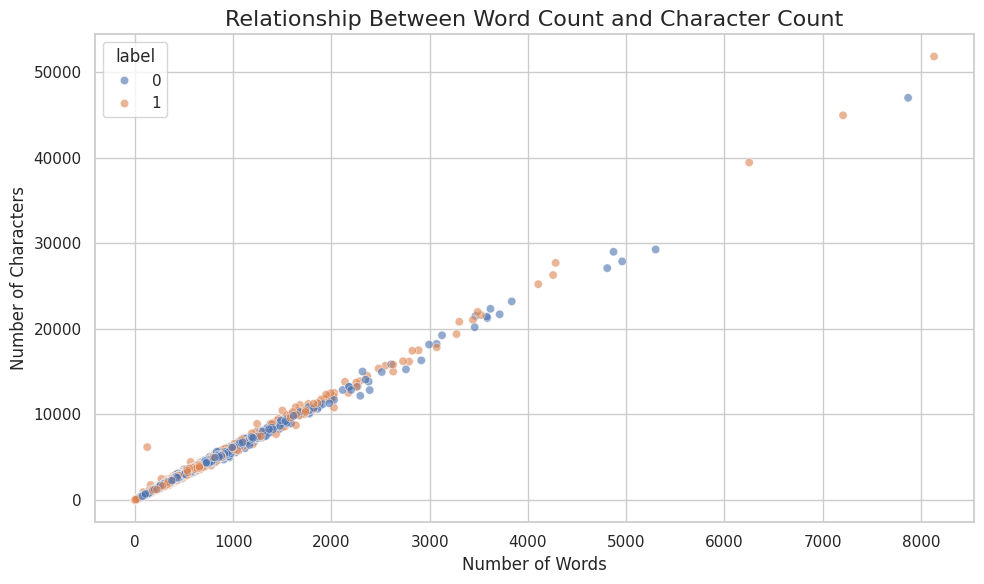

In [10]:
df["word_count"] = df["text"].fillna("").str.split().str.len()
df["char_count"] = df["text"].fillna("").str.len()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df.sample(min(3000, len(df)), random_state=42),
    x="word_count",
    y="char_count",
    hue="label",
    alpha=0.6
)

plt.title("Relationship Between Word Count and Character Count", fontsize=16)
plt.xlabel("Number of Words")
plt.ylabel("Number of Characters")

plt.tight_layout()
plt.show()

In [11]:
X = df[['title', 'text']]
y = df['label_encoded']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (72134, 2)
y shape: (72134,)


In [12]:
print("DUPLICATE AUDIT")
print("----------------")

print("Duplicate titles:",
      df['title'].dropna().duplicated().sum())

print("Duplicate article texts:",
      df['text'].dropna().duplicated().sum())

print("\nMissing values:")
print(df[['title', 'text', 'label']].isnull().sum())

print("\nConflicting labels for identical article texts:")

conflicts = (
    df.dropna(subset=['text'])
      .groupby('text')['label']
      .nunique()
)

print("Conflicting articles:", (conflicts > 1).sum())

DUPLICATE AUDIT
----------------
Duplicate titles: 9229
Duplicate article texts: 9377

Missing values:
title    558
text      39
label      0
dtype: int64

Conflicting labels for identical article texts:
Conflicting articles: 1


In [13]:
conflict_texts = conflicts[conflicts > 1].index

for article in conflict_texts:
    print(df.loc[
        df['text'] == article,
        ['title', 'label', 'label_encoded']
    ])

                                                                                                                    title  \
7                                         HOUSE INTEL CHAIR On Trump-Russia Fake Story: “No evidence of anything” [Video]   
106                                                  MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trump Bias May Be Suicidal   
325                   Ohio State University Student Says Terrorist Attack Was “Misunderstanding” Caused By Racism [VIDEO]   
364    JULIAN ASSANGE REVEALS John Podesta’s Hilarious Email Password…”A 14 Year Old Kid Could’ve Hacked Podesta” [VIDEO]   
512                                 OBAMA’S LIST OF 21 MEDAL OF FREEDOM Recipients Reads Like A Who’s Who Of The Far Left   
...                                                                                                                   ...   
71771                                           WOW! JILL STEIN’S ‘FIRESIDE CHAT’ Exposes Her Delusion On Recount [Video]   


In [14]:

conflict_rows = df[df['text'].isin(conflict_texts)]

print("Total rows:", len(conflict_rows))

print("\nLabel distribution:")
print(conflict_rows['label_encoded'].value_counts())

print("\nUnique labels per conflicting article:")
print(
    conflict_rows.groupby('text')['label_encoded']
    .agg(lambda x: sorted(x.unique()))
)

print("\nArticle text length:")
print(conflict_rows['text'].str.len().describe())

print("\nSample titles and labels:")
print(conflict_rows[['title', 'label', 'label_encoded']].head(15))

Total rows: 738

Label distribution:
label_encoded
1    737
0      1
Name: count, dtype: int64

Unique labels per conflicting article:
text
    [0, 1]
Name: label_encoded, dtype: object

Article text length:
count    738.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: text, dtype: float64

Sample titles and labels:
                                                                                                                                                   title  \
7                                                                        HOUSE INTEL CHAIR On Trump-Russia Fake Story: “No evidence of anything” [Video]   
106                                                                                 MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trump Bias May Be Suicidal   
325                                                  Ohio State University Student Says Terrorist Attack Was “Misunderstanding” Caused By Racism [VIDE

In [15]:
print("Unique conflicting text values:")
print(repr(conflict_rows['text'].iloc[0]))

print("\nRows with this text:")
print(conflict_rows[['title', 'text', 'label']].tail(5))

Unique conflicting text values:
' '

Rows with this text:
                                                                                        title  \
71771               WOW! JILL STEIN’S ‘FIRESIDE CHAT’ Exposes Her Delusion On Recount [Video]   
71914  WATCH TUCKER CARLSON Scorch Sanctuary City Mayor: “Don’t you believe in laws?” [Video]   
72026          BOOM! Woman Tries To Steal TRUMP Signs BUT This Guy Was Ready For Her! [Video]   
72119                         BILL O’REILLY Destroys Liberal Pundit On Trump Coverage [Video]   
72125               WOW! JILL STEIN’S ‘FIRESIDE CHAT’ Exposes Her Delusion On Recount [Video]   

      text  label  
71771           1  
71914           1  
72026           1  
72119           1  
72125           1  


In [16]:
df_clean = df[
    df['text'].fillna('').astype(str).str.strip().str.len() >= 20
].copy()

print("Original shape:", df.shape)
print("After removing unusable text:", df_clean.shape)

Original shape: (72134, 7)
After removing unusable text: (71253, 7)


In [17]:
# Remove exact duplicate article texts
df_clean = df_clean.drop_duplicates(
    subset=['text'],
    keep='first'
).copy()

print("Shape after duplicate removal:", df_clean.shape)

print("\nRemaining duplicate article texts:",
      df_clean['text'].duplicated().sum())

print("\nLabel distribution:")
print(df_clean['label_encoded'].value_counts())

print("\nLabel percentages:")
print(df_clean['label_encoded'].value_counts(normalize=True) * 100)

Shape after duplicate removal: (62643, 7)

Remaining duplicate article texts: 0

Label distribution:
label_encoded
0    34618
1    28025
Name: count, dtype: int64

Label percentages:
label_encoded
0    55.26236
1    44.73764
Name: proportion, dtype: float64


In [18]:
print("Missing values:")
print(df_clean[['title', 'text', 'label_encoded']].isnull().sum())

print("\nDuplicate article texts:",
      df_clean['text'].duplicated().sum())

print("\nConflicting labels for identical texts:")
conflicts_check = (
    df_clean.groupby('text')['label_encoded'].nunique()
)

print((conflicts_check > 1).sum())


Missing values:
title            482
text               0
label_encoded      0
dtype: int64

Duplicate article texts: 0

Conflicting labels for identical texts:
0


In [19]:
# Fill missing titles
df_clean['title'] = df_clean['title'].fillna('')

# Verify
print("Missing values after handling:")
print(df_clean[['title', 'text', 'label_encoded']].isnull().sum())

print("\nFinal dataset shape:", df_clean.shape)

print("\nFinal label distribution:")
print(df_clean['label_encoded'].value_counts())
X = df_clean[['title', 'text']]
y = df_clean['label_encoded']

print("X shape:", X.shape)
print("y shape:", y.shape)

Missing values after handling:
title            0
text             0
label_encoded    0
dtype: int64

Final dataset shape: (62643, 7)

Final label distribution:
label_encoded
0    34618
1    28025
Name: count, dtype: int64
X shape: (62643, 2)
y shape: (62643,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training input: (50114, 2)
Testing input: (12529, 2)

Training labels:
label_encoded
0    27694
1    22420
Name: count, dtype: int64

Testing labels:
label_encoded
0    6924
1    5605
Name: count, dtype: int64


In [21]:
train_texts = set(
    X_train['text'].astype(str).str.strip()
)

test_texts = set(
    X_test['text'].astype(str).str.strip()
)

train_texts.discard('')
test_texts.discard('')

common_texts = train_texts.intersection(test_texts)

print("Unique identical articles in both sets:",
      len(common_texts))

print("Training rows affected:",
      X_train['text'].astype(str).str.strip().isin(common_texts).sum())

print("Testing rows affected:",
      X_test['text'].astype(str).str.strip().isin(common_texts).sum())

Unique identical articles in both sets: 3
Training rows affected: 3
Testing rows affected: 3


In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

X_train = X_train.fillna('')
X_test = X_test.fillna('')

title_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2)
)

text_vectorizer = TfidfVectorizer(
    max_features=20000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_train_title = title_vectorizer.fit_transform(X_train['title'])
X_test_title = title_vectorizer.transform(X_test['title'])

X_train_text = text_vectorizer.fit_transform(X_train['text'])
X_test_text = text_vectorizer.transform(X_test['text'])

print("Title training:", X_train_title.shape)
print("Title testing:", X_test_title.shape)

print("Text training:", X_train_text.shape)
print("Text testing:", X_test_text.shape)

Title training: (50114, 5000)
Title testing: (12529, 5000)
Text training: (50114, 20000)
Text testing: (12529, 20000)


In [23]:
X_train_tfidf = hstack(
    [X_train_title, X_train_text]
).tocsr()

X_test_tfidf = hstack(
    [X_test_title, X_test_text]
).tocsr()

print("Combined training:", X_train_tfidf.shape)
print("Combined testing:", X_test_tfidf.shape)

Combined training: (50114, 25000)
Combined testing: (12529, 25000)


In [24]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Predictions
y_train_pred_lr = lr_model.predict(X_train_tfidf)
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Training Accuracy:",
      round(accuracy_score(y_train, y_train_pred_lr) * 100, 2), "%")

print("Testing Accuracy:",
      round(accuracy_score(y_test, y_pred_lr) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Fake', 'Real']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Training Accuracy: 97.95 %
Testing Accuracy: 96.65 %

Classification Report:
              precision    recall  f1-score   support

        Fake       0.97      0.97      0.97      6924
        Real       0.96      0.97      0.96      5605

    accuracy                           0.97     12529
   macro avg       0.97      0.97      0.97     12529
weighted avg       0.97      0.97      0.97     12529


Confusion Matrix:
[[6688  236]
 [ 184 5421]]


In [26]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=2000
)

# Train
svm_model.fit(X_train_tfidf, y_train)

# Predictions
y_train_pred_svm = svm_model.predict(X_train_tfidf)
y_pred_svm = svm_model.predict(X_test_tfidf)

print("SVM training completed.")

SVM training completed.


In [27]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Training Accuracy:",
      round(accuracy_score(y_train, y_train_pred_svm) * 100, 2), "%")

print("Testing Accuracy:",
      round(accuracy_score(y_test, y_pred_svm) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=['Fake', 'Real']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

Training Accuracy: 99.91 %
Testing Accuracy: 97.09 %

Classification Report:
              precision    recall  f1-score   support

        Fake       0.98      0.97      0.97      6924
        Real       0.96      0.97      0.97      5605

    accuracy                           0.97     12529
   macro avg       0.97      0.97      0.97     12529
weighted avg       0.97      0.97      0.97     12529


Confusion Matrix:
[[6724  200]
 [ 165 5440]]


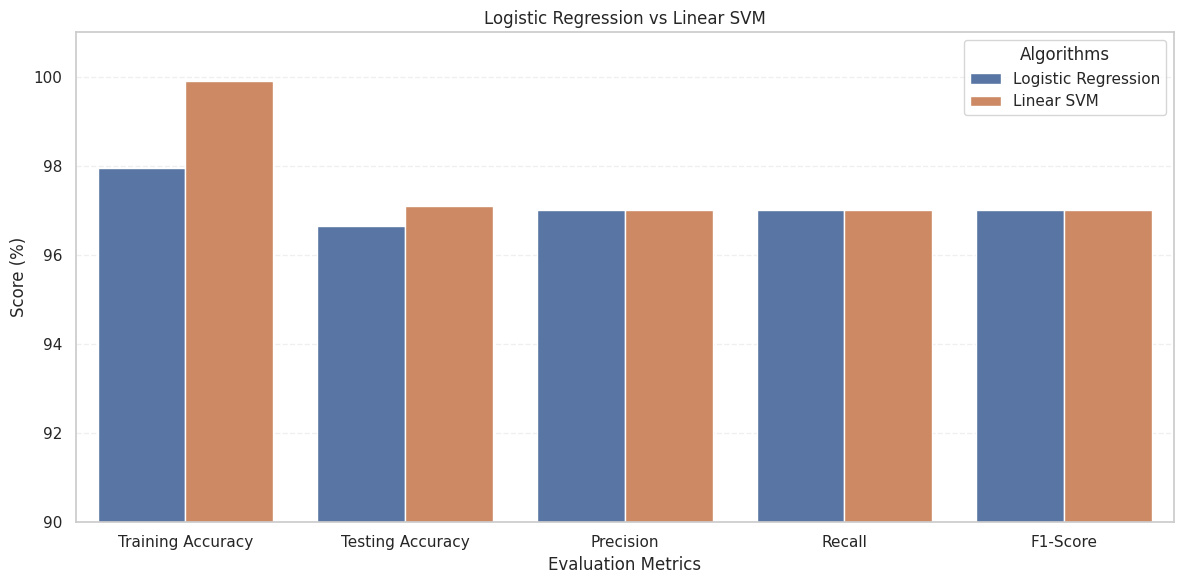

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

comparison = pd.DataFrame({
    'Algorithm': [
        'Logistic Regression', 'Logistic Regression',
        'Logistic Regression', 'Logistic Regression',
        'Logistic Regression',
        'Linear SVM', 'Linear SVM',
        'Linear SVM', 'Linear SVM', 'Linear SVM'
    ],
    'Metric': [
        'Training Accuracy', 'Testing Accuracy',
        'Precision', 'Recall', 'F1-Score',
        'Training Accuracy', 'Testing Accuracy',
        'Precision', 'Recall', 'F1-Score'
    ],
    'Score': [
        97.95, 96.65, 97, 97, 97,
        99.91, 97.09, 97, 97, 97
    ]
})

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison,
    x='Metric',
    y='Score',
    hue='Algorithm'
)

plt.title('Logistic Regression vs Linear SVM')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score (%)')
plt.ylim(90, 101)
plt.legend(title='Algorithms')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:

from sklearn.naive_bayes import MultinomialNB

# Create Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Make predictions
y_train_pred_nb = nb_model.predict(X_train_tfidf)
y_pred_nb = nb_model.predict(X_test_tfidf)

print("Naive Bayes Model Training Completed!")


Naive Bayes Model Training Completed!


In [30]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Training Accuracy
train_accuracy_nb = accuracy_score(y_train, y_train_pred_nb)

# Testing Accuracy
test_accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Training Accuracy:",
      round(train_accuracy_nb * 100, 2), "%")

print("Naive Bayes Testing Accuracy:",
      round(test_accuracy_nb * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Fake', 'Real']
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))


Naive Bayes Training Accuracy: 90.56 %
Naive Bayes Testing Accuracy: 90.07 %

Classification Report:
              precision    recall  f1-score   support

        Fake       0.92      0.90      0.91      6924
        Real       0.88      0.90      0.89      5605

    accuracy                           0.90     12529
   macro avg       0.90      0.90      0.90     12529
weighted avg       0.90      0.90      0.90     12529


Confusion Matrix:
[[6219  705]
 [ 539 5066]]


In [31]:

from sklearn.decomposition import TruncatedSVD

# Reduce TF-IDF dimensions
svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

print("Original Training Shape:", X_train_tfidf.shape)
print("Reduced Training Shape:", X_train_svd.shape)

print("Original Testing Shape:", X_test_tfidf.shape)
print("Reduced Testing Shape:", X_test_svd.shape)

print("SVD Feature Reduction Completed!")


Original Training Shape: (50114, 25000)
Reduced Training Shape: (50114, 50)
Original Testing Shape: (12529, 25000)
Reduced Testing Shape: (12529, 50)
SVD Feature Reduction Completed!


In [32]:

from sklearn.neighbors import KNeighborsClassifier
import numpy as np

# Select random training samples
rng = np.random.RandomState(42)
sample_size = min(15000, len(X_train_svd))

sample_indices = rng.choice(
    len(X_train_svd),
    size=sample_size,
    replace=False
)

X_knn_train = X_train_svd[sample_indices]
y_knn_train = y_train.iloc[sample_indices]

# Create KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='cosine',
    algorithm='brute',
    n_jobs=-1
)

# Train model
knn_model.fit(X_knn_train, y_knn_train)

print("KNN Model Training Completed!")
print("Training Samples Used:", sample_size)


KNN Model Training Completed!
Training Samples Used: 15000


In [33]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions
y_pred_knn = knn_model.predict(X_test_svd)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Testing Accuracy:",
      round(knn_accuracy * 100, 2), "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=['Fake', 'Real']
))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))


KNN Testing Accuracy: 89.5 %

Classification Report:
              precision    recall  f1-score   support

        Fake       0.90      0.91      0.91      6924
        Real       0.89      0.87      0.88      5605

    accuracy                           0.90     12529
   macro avg       0.89      0.89      0.89     12529
weighted avg       0.89      0.90      0.89     12529


Confusion Matrix:
[[6330  594]
 [ 721 4884]]


Algorithm Performance Comparison:


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,96.65,96.65,96.65,96.65
1,Linear SVM,97.09,97.09,97.09,97.09
2,Naive Bayes,90.07,90.13,90.07,90.08
3,KNN,89.50,89.50,89.50,89.49


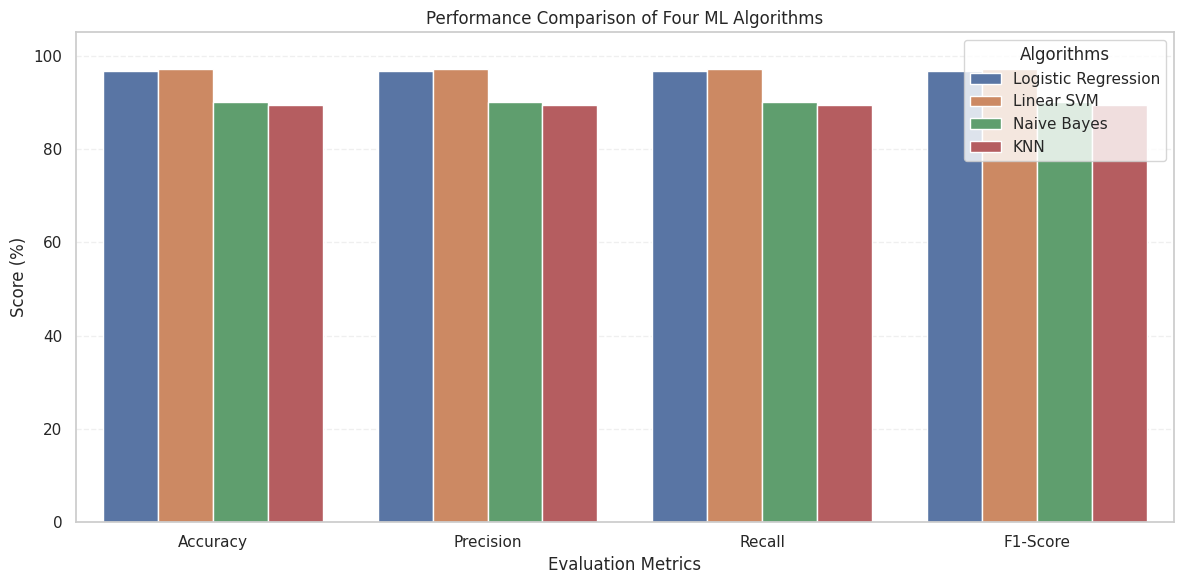

In [34]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate testing metrics for all models
models = {
    'Logistic Regression': y_pred_lr,
    'Linear SVM': y_pred_svm,
    'Naive Bayes': y_pred_nb,
    'KNN': y_pred_knn
}

results = []

for name, predictions in models.items():
    results.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, predictions) * 100,
        'Precision': precision_score(y_test, predictions, average='weighted') * 100,
        'Recall': recall_score(y_test, predictions, average='weighted') * 100,
        'F1-Score': f1_score(y_test, predictions, average='weighted') * 100
    })

comparison_df = pd.DataFrame(results)

print("Algorithm Performance Comparison:")
display(comparison_df.round(2))

# Convert data for graph
comparison_plot = comparison_df.melt(
    id_vars='Algorithm',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x='Metric',
    y='Score',
    hue='Algorithm'
)

plt.title("Performance Comparison of Four ML Algorithms")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.legend(title="Algorithms")
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


In [35]:
# Decision Tree

from sklearn.feature_selection import SelectKBest, chi2

# Decision Trees are slow on 25,000 sparse features,
# so keep the 3,000 most informative ones
selector = SelectKBest(score_func=chi2, k=3000)

X_train_dt = selector.fit_transform(X_train_tfidf, y_train)
X_test_dt = selector.transform(X_test_tfidf)

print("Original shape:", X_train_tfidf.shape)
print("Reduced shape :", X_train_dt.shape)

Original shape: (50114, 25000)
Reduced shape : (50114, 3000)


In [36]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# An unrestricted tree memorises the training data (overfitting),
# so tune the depth and leaf size with cross-validation
param_grid = {
    'max_depth': [10, 15, 20],
    'min_samples_leaf': [5, 10]
}

grid = GridSearchCV(
    DecisionTreeClassifier(criterion='gini', random_state=42),
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train_dt, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", round(grid.best_score_ * 100, 2), "%")

dt_model = grid.best_estimator_

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 5}
Best CV Accuracy: 93.75 %


In [37]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_train_pred_dt = dt_model.predict(X_train_dt)
y_pred_dt = dt_model.predict(X_test_dt)

print("Decision Tree Training Accuracy:",
      round(accuracy_score(y_train, y_train_pred_dt) * 100, 2), "%")
print("Decision Tree Testing Accuracy:",
      round(accuracy_score(y_test, y_pred_dt) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, target_names=['Fake', 'Real']))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Training Accuracy: 94.36 %
Decision Tree Testing Accuracy: 94.01 %

Classification Report:
              precision    recall  f1-score   support

        Fake       0.97      0.92      0.94      6924
        Real       0.91      0.96      0.94      5605

    accuracy                           0.94     12529
   macro avg       0.94      0.94      0.94     12529
weighted avg       0.94      0.94      0.94     12529


Confusion Matrix:
[[6373  551]
 [ 199 5406]]


In [38]:
# Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,        # number of trees in the forest
    min_samples_leaf=2,      # stops trees from memorising single articles
    max_features='sqrt',     # each split considers a random subset of features
    n_jobs=-1,               # use all CPU cores
    random_state=42
)

rf_model.fit(X_train_dt, y_train)

y_train_pred_rf = rf_model.predict(X_train_dt)
y_pred_rf = rf_model.predict(X_test_dt)

print("Random Forest training completed.")

Random Forest training completed.


In [39]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Random Forest Training Accuracy:",
      round(accuracy_score(y_train, y_train_pred_rf) * 100, 2), "%")
print("Random Forest Testing Accuracy:",
      round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Fake', 'Real']))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Training Accuracy: 99.49 %
Random Forest Testing Accuracy: 95.5 %

Classification Report:
              precision    recall  f1-score   support

        Fake       0.97      0.95      0.96      6924
        Real       0.94      0.96      0.95      5605

    accuracy                           0.95     12529
   macro avg       0.95      0.96      0.95     12529
weighted avg       0.96      0.95      0.96     12529


Confusion Matrix:
[[6578  346]
 [ 218 5387]]


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,96.65,96.65,96.65,96.65
1,Linear SVM,97.09,97.09,97.09,97.09
2,Naive Bayes,90.07,90.13,90.07,90.08
3,KNN,89.50,89.50,89.50,89.49
4,Decision Tree,94.01,94.19,94.01,94.03
5,Random Forest,95.50,95.53,95.50,95.50


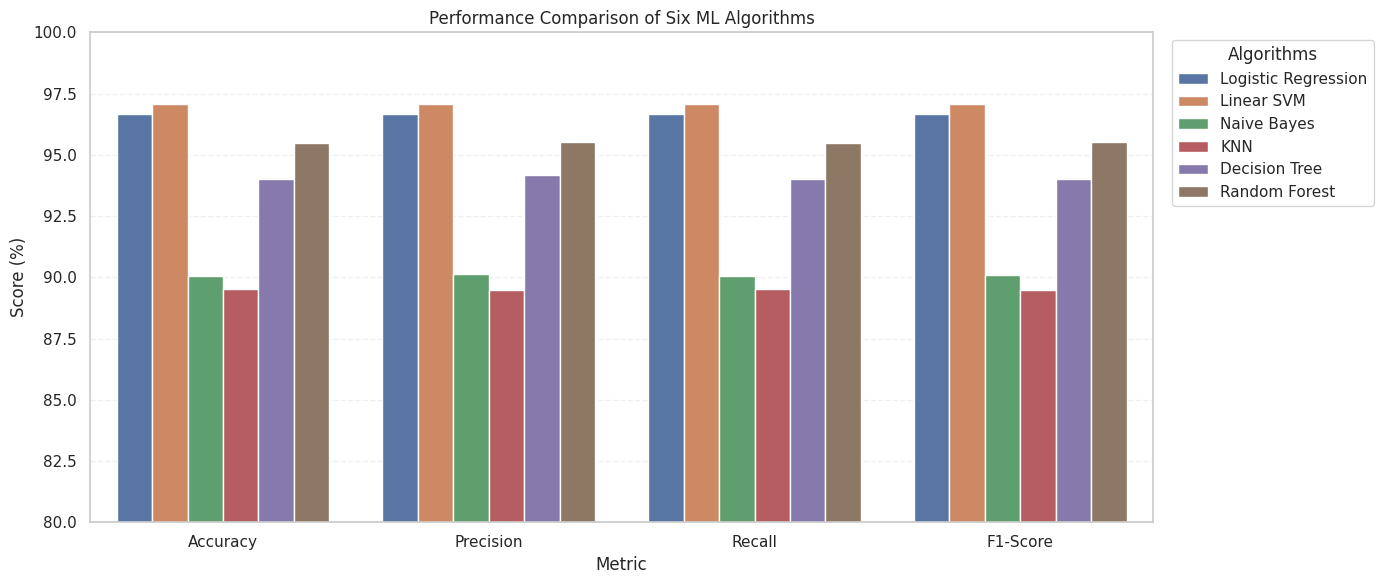

In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

models = {
    'Logistic Regression': y_pred_lr,
    'Linear SVM': y_pred_svm,
    'Naive Bayes': y_pred_nb,
    'KNN': y_pred_knn,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf
}

results = []
for name, pred in models.items():
    results.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, pred) * 100,
        'Precision': precision_score(y_test, pred, average='weighted') * 100,
        'Recall': recall_score(y_test, pred, average='weighted') * 100,
        'F1-Score': f1_score(y_test, pred, average='weighted') * 100
    })

comparison_df = pd.DataFrame(results)
display(comparison_df.round(2))

comparison_plot = comparison_df.melt(id_vars='Algorithm',
                                     var_name='Metric', value_name='Score')

plt.figure(figsize=(14, 6))
sns.barplot(data=comparison_plot, x='Metric', y='Score', hue='Algorithm')
plt.title('Performance Comparison of Six ML Algorithms')
plt.ylabel('Score (%)')
plt.ylim(80, 100)
plt.legend(title='Algorithms', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()